# BRCA ST patient H — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **H**: patient 24044, sections H1–H3, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=H bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import io
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    cmd_plot,
)

PATIENT = "H"
PREVIEW_PX = 1100
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


def show_preview(path: Path) -> None:
    """Embed a small JPEG. The full PNG stays on disk."""
    im = PILImage.open(path)
    im.thumbnail((PREVIEW_PX, PREVIEW_PX))
    buf = io.BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=70)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(path)


H  n=3
HE_BT24044_D2  mpp=0.6867 µm/px  native16=10.99 µm  after rescale=8.0 µm  scale=1.3733  (ST 200 µm spot pitch (H1))
  pred exists: True
HE_BT24044_E1  mpp=0.6867 µm/px  native16=10.99 µm  after rescale=8.0 µm  scale=1.3733  (ST 200 µm spot pitch (H2))
  pred exists: True
HE_BT24044_E2  mpp=0.6866 µm/px  native16=10.99 µm  after rescale=8.0 µm  scale=1.3732  (ST 200 µm spot pitch (H3))
  pred exists: True


## H — composition and spatial labels


===== H L1 =====


fraction                                 mean_conf  \
sample      HE_BT24044_D2 HE_BT24044_E1 HE_BT24044_E2 HE_BT24044_D2   
class                                                                 
Immune              0.634         0.639         0.637         0.642   
Endothelial         0.195         0.203         0.212         0.487   
Stromal             0.107         0.071         0.113         0.450   
Epithelial          0.064         0.087         0.038         0.568   

                                                    n                \
sample      HE_BT24044_E1 HE_BT24044_E2 HE_BT24044_D2 HE_BT24044_E1   
class                                                                 
Immune              0.642         0.659       54391.0       51526.0   
Endothelial         0.485         0.507       16694.0       16391.0   
Stromal             0.434         0.458        9210.0        5744.0   
Epithelial          0.585         0.551        5521.0        7010.0   

                           
sample      HE_BT24044_E2  
class                      
Immune            39424.0  
Endothelial       13127.0  
Stromal            6966.0  
Epithelial         2371.0

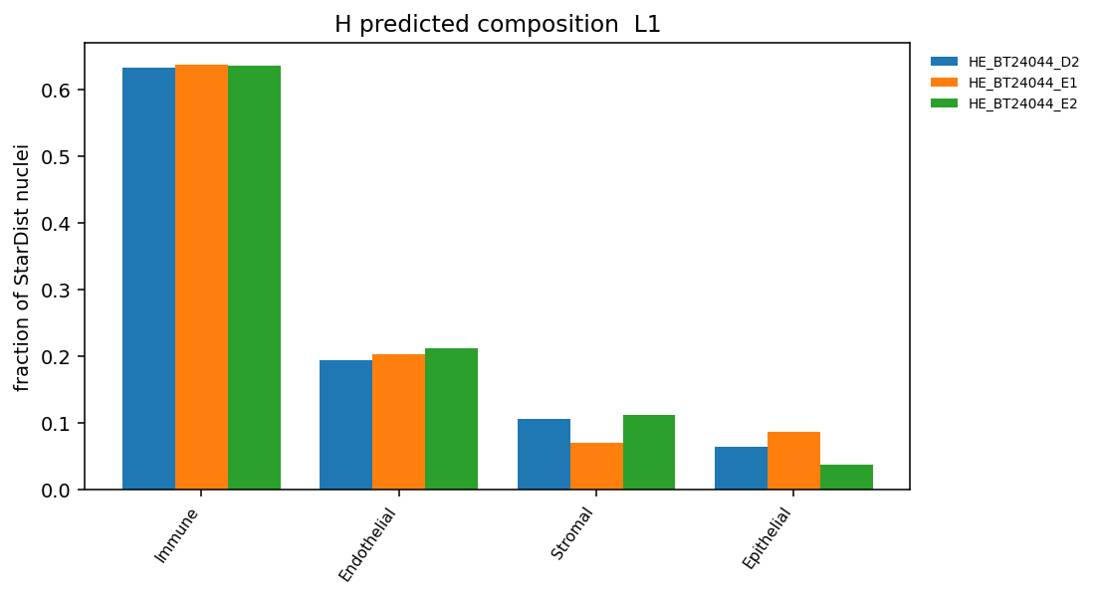

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/H_composition_L1.png

===== H L12 =====


fraction                                 mean_conf  \
sample      HE_BT24044_D2 HE_BT24044_E1 HE_BT24044_E2 HE_BT24044_D2   
class                                                                 
T_cell              0.652         0.618         0.663         0.492   
Stromal             0.148         0.120         0.148         0.371   
B_Plasma            0.065         0.098         0.062         0.436   
Epithelial          0.053         0.064         0.025         0.510   
Endothelial         0.041         0.046         0.057         0.343   
Myeloid             0.039         0.046         0.040         0.331   
Tumor               0.002         0.007         0.005         0.373   

                                                    n                \
sample      HE_BT24044_E1 HE_BT24044_E2 HE_BT24044_D2 HE_BT24044_E1   
class                                                                 
T_cell              0.479         0.515       55977.0       49876.0   
Stromal             0.353         0.373       12709.0        9673.0   
B_Plasma            0.449         0.446        5569.0        7877.0   
Epithelial          0.510         0.470        4540.0        5203.0   
Endothelial         0.338         0.353        3509.0        3749.0   
Myeloid             0.324         0.324        3328.0        3726.0   
Tumor               0.399         0.428         184.0         567.0   

                           
sample      HE_BT24044_E2  
class                      
T_cell            41044.0  
Stromal            9180.0  
B_Plasma           3824.0  
Epithelial         1527.0  
Endothelial        3539.0  
Myeloid            2463.0  
Tumor               311.0

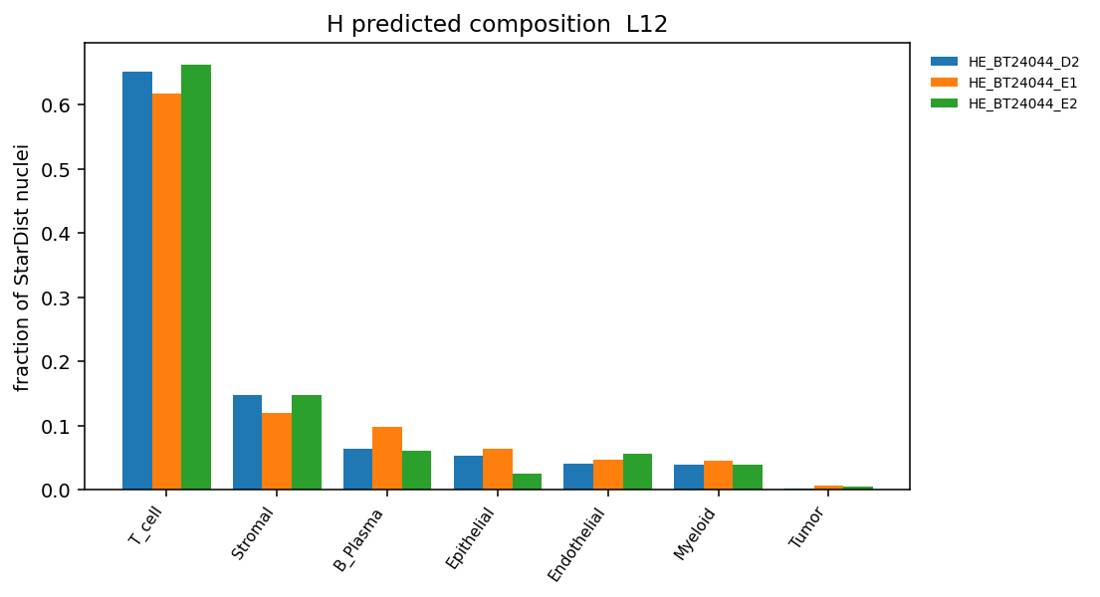

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/H_composition_L12.png

===== H L2 =====


fraction                                 mean_conf  \
sample            HE_BT24044_D2 HE_BT24044_E1 HE_BT24044_E2 HE_BT24044_D2   
class                                                                       
B_cell                    0.571         0.611         0.544         0.447   
Endothelial               0.120         0.125         0.138         0.282   
CD4_T                     0.105         0.086         0.121         0.320   
Fibroblast                0.097         0.080         0.113         0.258   
Injury_epithelial         0.023         0.030         0.009         0.389   
Stromal                   0.026         0.009         0.019         0.318   
Epithelial                0.016         0.016         0.008         0.286   
CD8_T                     0.011         0.014         0.007         0.236   
Neutrophil                0.005         0.004         0.013         0.218   
Plasma                    0.010         0.005         0.006         0.258   
Tregs                     0.004         0.001         0.008         0.248   
DC                        0.007         0.006         0.004         0.276   
DCIS                      0.002         0.005         0.006         0.280   
Tumor                     0.001         0.004         0.001         0.287   
Myoepithelial             0.003         0.003         0.001         0.223   
Macrophage                0.000         0.001         0.000         0.160   
Myofibroblast             0.000         0.001         0.000         0.223   
Alveolar                  0.000         0.000         0.000         0.173   
NK                        0.000         0.000         0.000         0.215   

                                                          n                \
sample            HE_BT24044_E1 HE_BT24044_E2 HE_BT24044_D2 HE_BT24044_E1   
class                                                                       
B_cell                    0.468         0.463       48998.0       49314.0   
Endothelial               0.281         0.299       10316.0       10063.0   
CD4_T                     0.307         0.336        8997.0        6948.0   
Fibroblast                0.258         0.283        8316.0        6476.0   
Injury_epithelial         0.369         0.350        1931.0        2391.0   
Stromal                   0.296         0.313        2194.0         688.0   
Epithelial                0.295         0.271        1331.0        1320.0   
CD8_T                     0.240         0.237         934.0        1127.0   
Neutrophil                0.223         0.224         431.0         293.0   
Plasma                    0.261         0.253         819.0         404.0   
Tregs                     0.256         0.257         337.0          54.0   
DC                        0.278         0.280         638.0         505.0   
DCIS                      0.341         0.417         192.0         380.0   
Tumor                     0.299         0.278         109.0         335.0   
Myoepithelial             0.207         0.214         221.0         214.0   
Macrophage                0.168         0.166          34.0          94.0   
Myofibroblast             0.230         0.223           6.0          41.0   
Alveolar                  0.229         0.185           8.0          15.0   
NK                        0.184         0.171           4.0           9.0   

                                 
sample            HE_BT24044_E2  
class                            
B_cell                  33689.0  
Endothelial              8556.0  
CD4_T                    7474.0  
Fibroblast               7007.0  
Injury_epithelial         536.0  
Stromal                  1153.0  
Epithelial                515.0  
CD8_T                     438.0  
Neutrophil                805.0  
Plasma                    382.0  
Tregs                     506.0  
DC                        251.0  
DCIS                      387.0  
Tumor                      83.0  
Myoepithelial              68.0  
Macrophage           

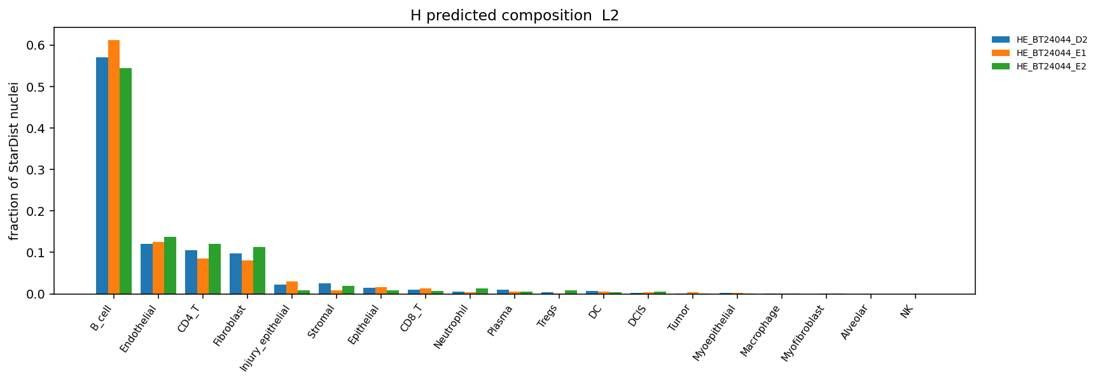

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/H_composition_L2.png
HE_BT24044_D2


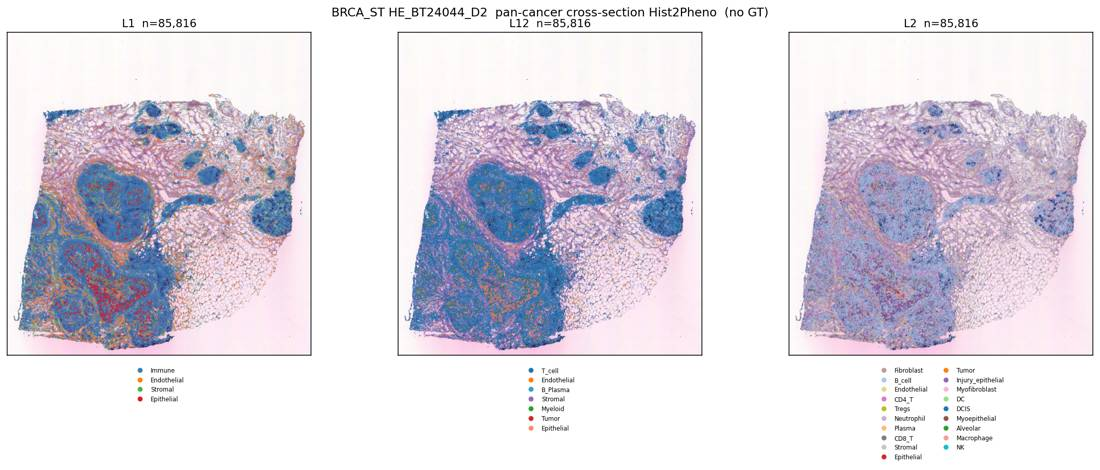

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_D2_spatial_L1_L12_L2.png
HE_BT24044_E1


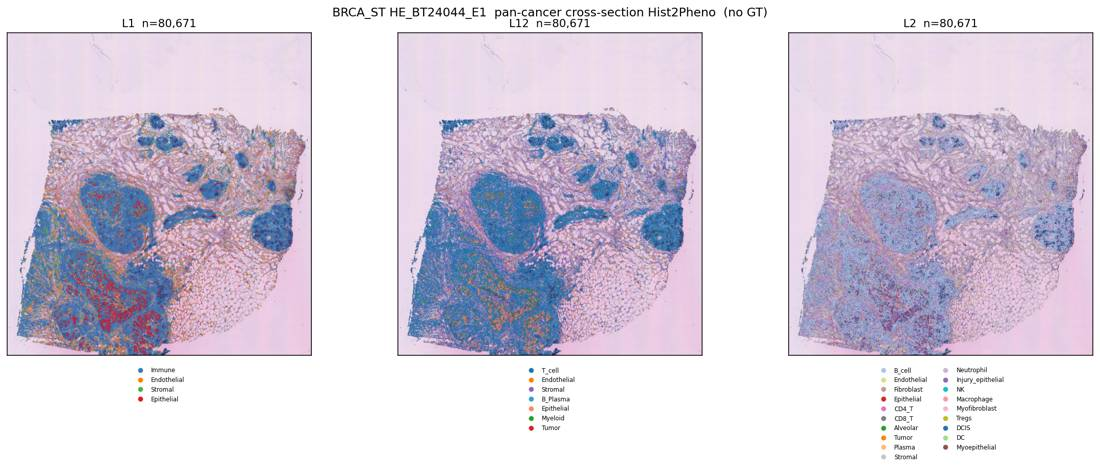

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E1_spatial_L1_L12_L2.png
HE_BT24044_E2


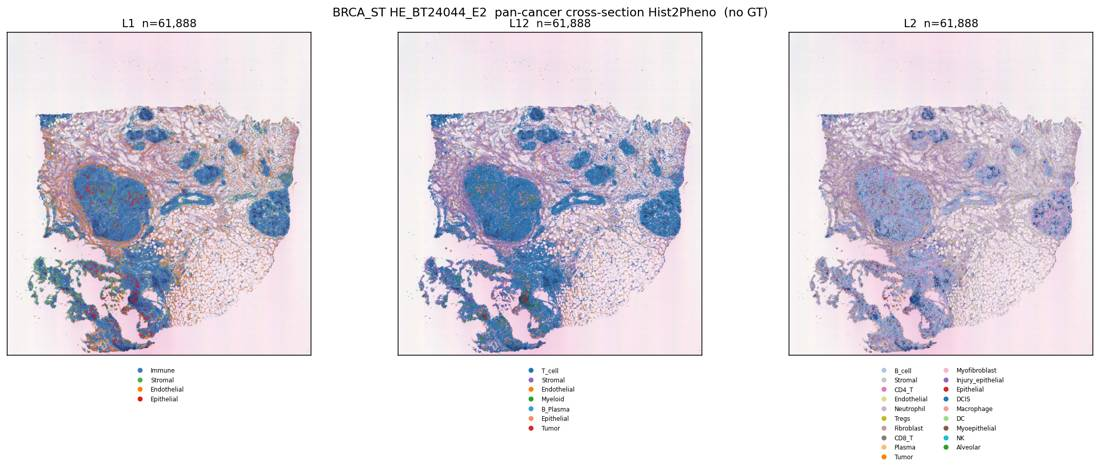

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E2_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    out = fig_dir / f"{PATIENT}_composition_{head}.png"
    fig.savefig(out, dpi=140, bbox_inches="tight")
    plt.close(fig)
    show_preview(out)

spatial_missing = [
    s for s in group if not (fig_dir / f"{s}_spatial_L1_L12_L2.png").is_file()
]
if spatial_missing:
    cmd_plot(group)
    for head in ("L1", "L12", "L2"):
        src = fig_dir / f"composition_{head}.png"
        if src.is_file():
            shutil.copy(src, fig_dir / f"{PATIENT}_composition_{head}.png")
for sample in group:
    print(sample)
    show_preview(fig_dir / f"{sample}_spatial_L1_L12_L2.png")


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## H — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT24044_D2/HE_BT24044_D2_l2_probs.npz  (85816, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT24044_D2/HE_BT24044_D2_niche_indices.h5ad  n=85,816
  TLS hotspot: {'n_cells_total': 85816, 'n_candidate_cells': 4291, 'fraction_candidate': 0.0500023305677263, 'max_tls_spatial': 0.24300828943401817, 'mean_tls_spatial_candidate': 0.19963846256915324, 'centroid_x': 3374.168352174859, 'centroid_y': 6349.441238266414}
  mean TLS=0.632  TLS_spatial=0.147  SRI=12.957  TNI=23.124
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT24044_E1/HE_BT24044_E1_l2_probs.npz  (80671, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT24044_E1/HE_BT24044_E1_niche_indices.h5ad  n=80,671
  TLS hotspot: {'n_cells_total': 80671, 'n_candidate_cells': 4034, 'fraction_candida

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,HE_BT24044_D2,85816,0.632,0.675,0.960,0.993,0.147,0.159,0.191,0.243,0.684,0.631,0.035,0.067,0.171,0.787
1,HE_BT24044_E1,80671,0.633,0.688,0.959,0.992,0.146,0.158,0.190,0.227,0.719,0.674,0.051,0.096,0.173,0.832
2,HE_BT24044_E2,61888,0.633,0.680,0.963,0.995,0.142,0.155,0.185,0.235,0.723,0.665,0.018,0.036,0.164,0.777


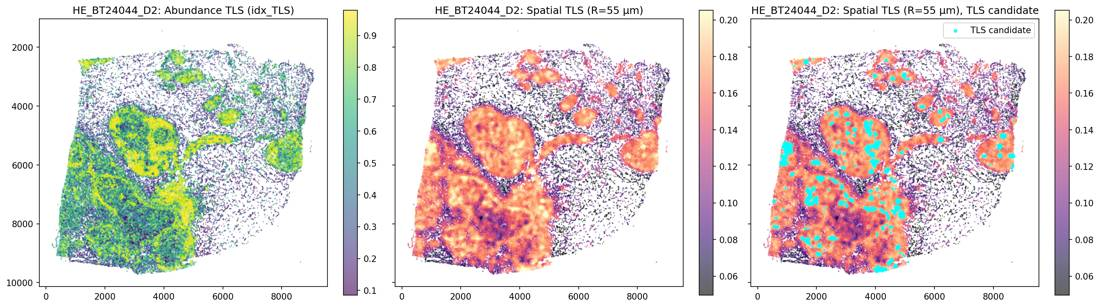

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_D2_TLS_abundance_vs_spatial.png


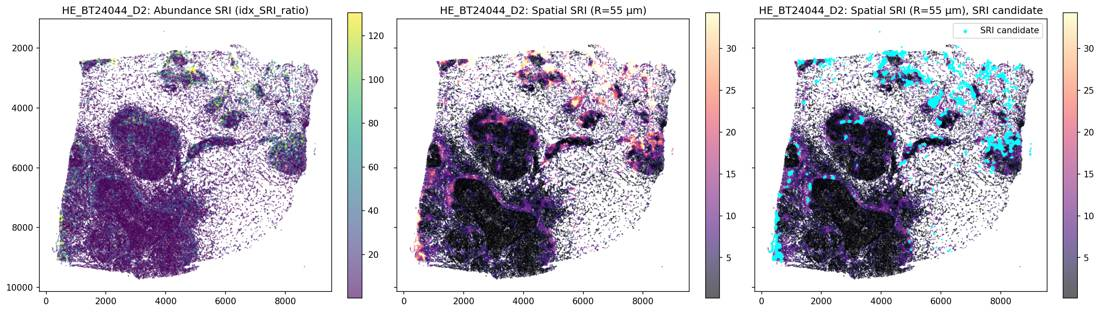

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_D2_SRI_abundance_vs_spatial.png


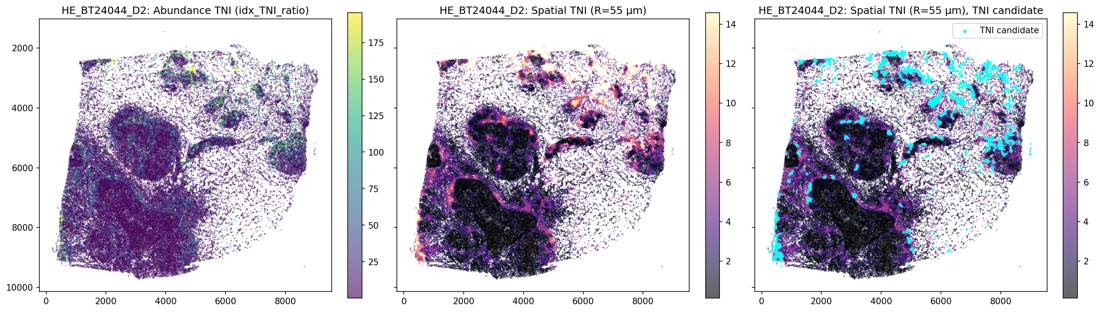

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_D2_TNI_abundance_vs_spatial.png


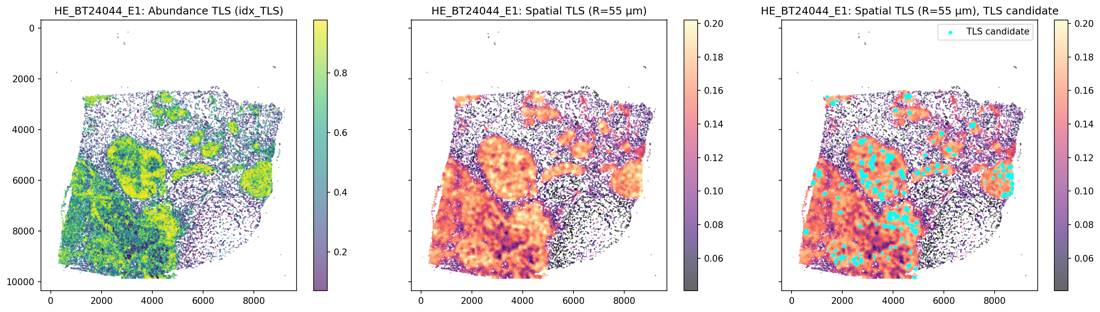

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E1_TLS_abundance_vs_spatial.png


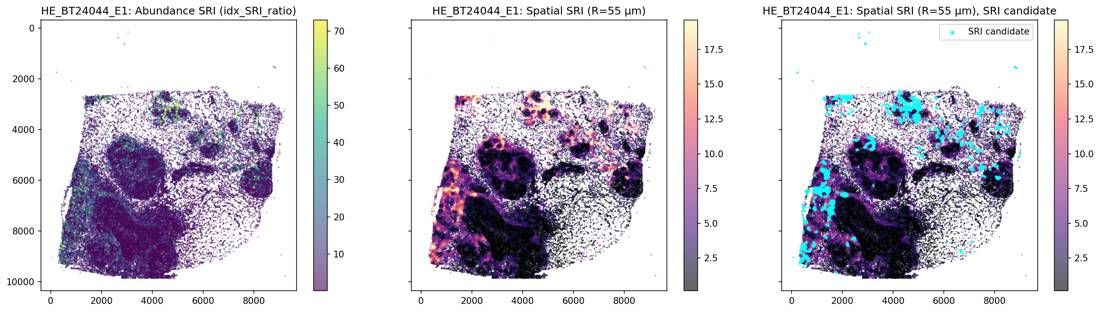

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E1_SRI_abundance_vs_spatial.png


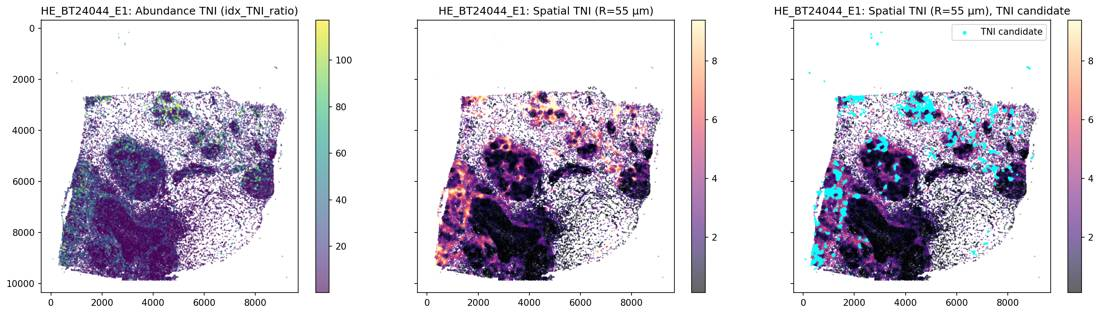

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E1_TNI_abundance_vs_spatial.png


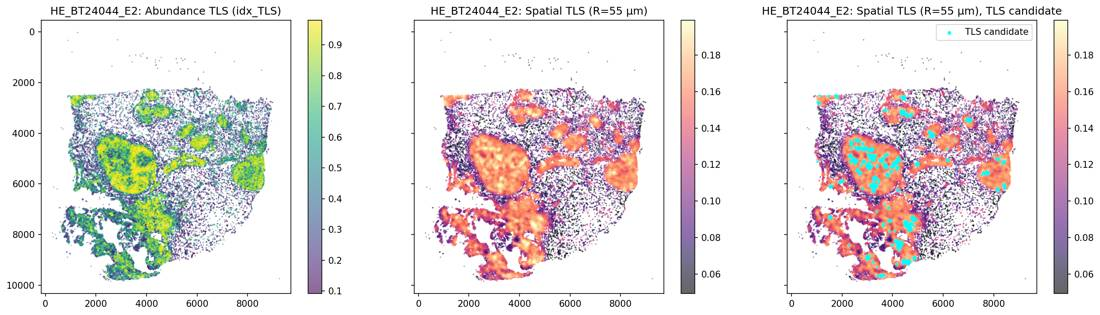

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E2_TLS_abundance_vs_spatial.png


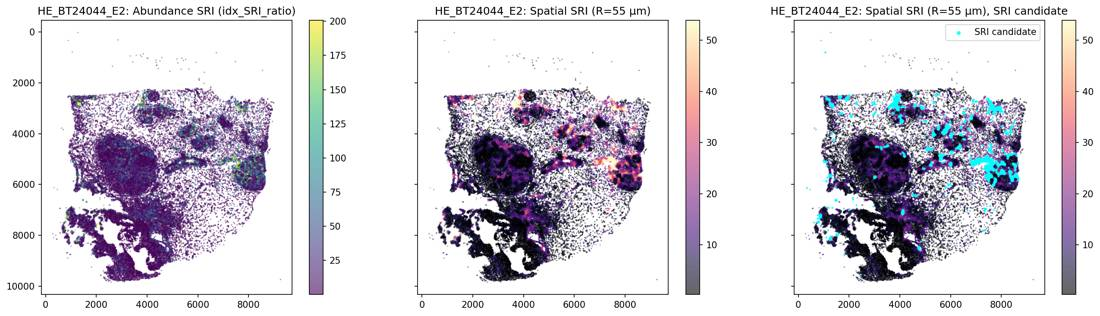

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E2_SRI_abundance_vs_spatial.png


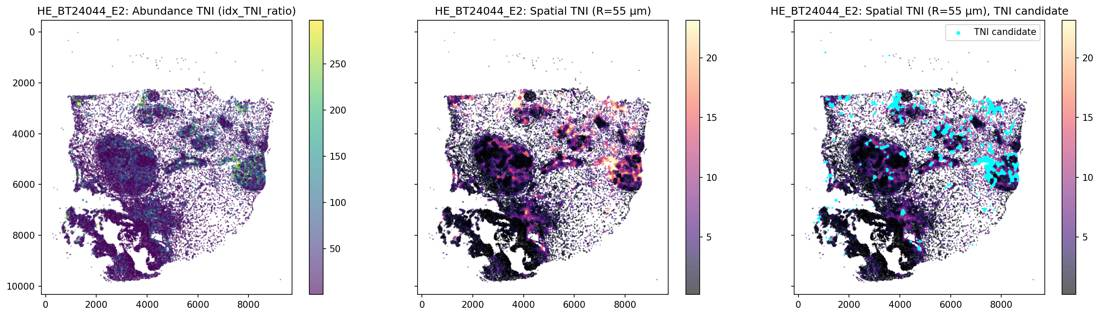

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT24044_E2_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=fig_dir / f"{sample}_TLS_abundance_vs_spatial.png",
    )
    plt.close(fig)
    show_preview(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png")
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png",
        )
        plt.close(fig)
        show_preview(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png")
